Lima baris pertama dataset:
         X   Y_Aktual
0 -5.00000  67.483571
1 -4.89899  62.005852
2 -4.79798  63.673602
3 -4.69697  65.829107
4 -4.59596  54.862801

Hasil R-squared:
Model Buruk (Rata-rata): 0.0000
Model Linear: 0.2193
Model Polinomial: 0.9391


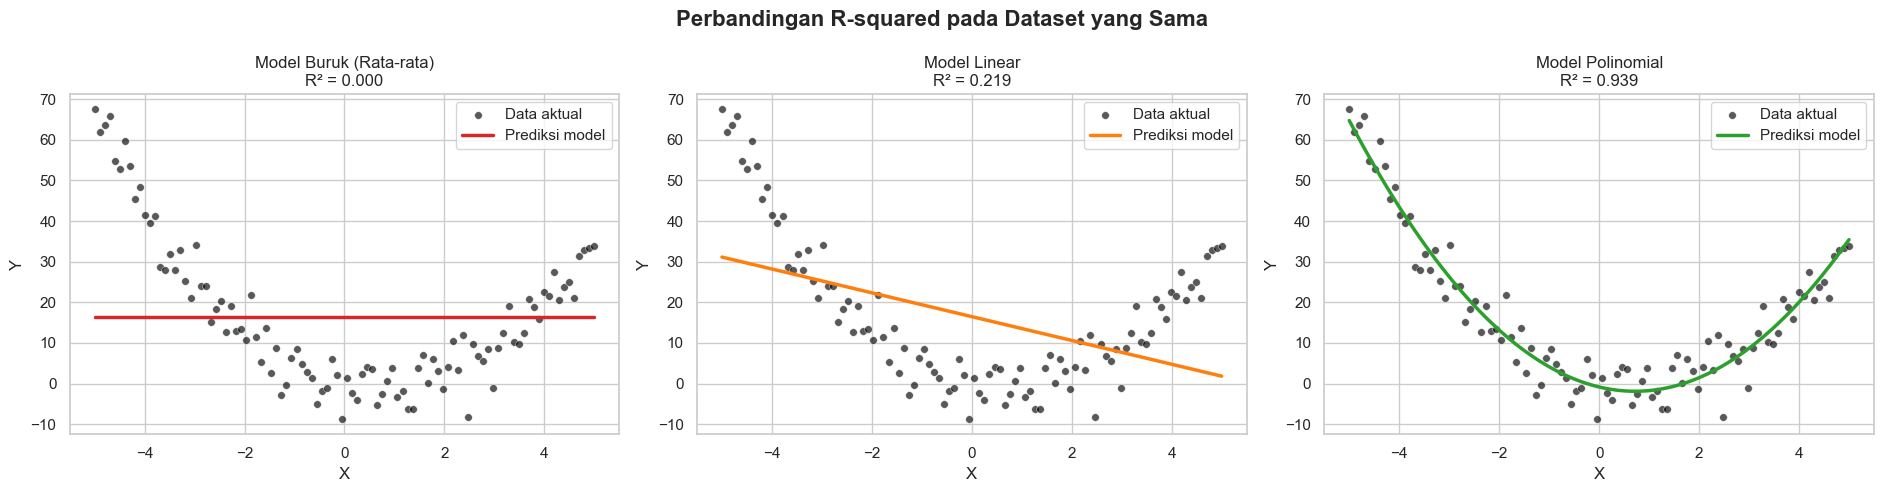

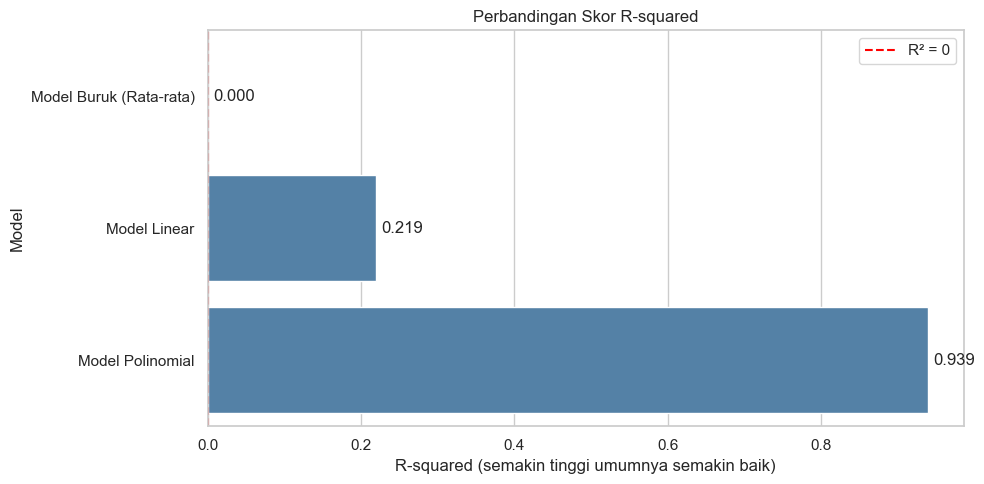


Tabel perbandingan:
             Nama Model  R-squared
Model Buruk (Rata-rata)   0.000000
           Model Linear   0.219262
       Model Polinomial   0.939074


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. MEMBUAT SATU DATASET YANG SAMA UNTUK SEMUA MODEL
# ============================================================

np.random.seed(42)

n = 100

X = np.linspace(-5, 5, n)
noise = np.random.normal(0, 5, n)

# Hubungan nonlinear: y = 2x² - 3x + noise
y = 2 * X**2 - 3 * X + noise

df = pd.DataFrame({
    "X": X,
    "Y_Aktual": y
})

print("Lima baris pertama dataset:")
print(df.head())

# ============================================================
# 2. MEMBUAT TIGA MODEL DENGAN KUALITAS BERBEDA
#    Semua model memprediksi dataset yang sama!
# ============================================================

# MODEL 1: Model buruk
# Hanya memprediksi nilai rata-rata Y untuk semua X.
y_pred_buruk = np.full(n, np.mean(y))

# MODEL 2: Model cukup baik
# Menggunakan regresi linear (garis lurus).
koef_linear = np.polyfit(X, y, deg=1)
y_pred_linear = np.polyval(koef_linear, X)

# MODEL 3: Model sangat baik
# Menggunakan regresi polinomial derajat 2 (kurva).
koef_polinomial = np.polyfit(X, y, deg=2)
y_pred_polinomial = np.polyval(koef_polinomial, X)

# ============================================================
# 3. MENGHITUNG R-SQUARED TANPA SKLEARN
# ============================================================

def hitung_r_squared(y_aktual, y_prediksi):
    ss_res = np.sum((y_aktual - y_prediksi) ** 2)
    ss_tot = np.sum((y_aktual - np.mean(y_aktual)) ** 2)

    return 1 - (ss_res / ss_tot)


hasil = {
    "Model Buruk (Rata-rata)": y_pred_buruk,
    "Model Linear": y_pred_linear,
    "Model Polinomial": y_pred_polinomial
}

r2_scores = {
    nama: hitung_r_squared(y, prediksi)
    for nama, prediksi in hasil.items()
}

print("\nHasil R-squared:")
for nama, skor in r2_scores.items():
    print(f"{nama}: {skor:.4f}")

# ============================================================
# 4. MENYIAPKAN DATA UNTUK VISUALISASI
# ============================================================

df_plot = df.copy()

for nama, prediksi in hasil.items():
    df_plot[nama] = prediksi

sns.set_theme(style="whitegrid", context="notebook")

# ============================================================
# 5. VISUALISASI: MEMBANDINGKAN PREDIKSI MODEL
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

warna = ["tab:red", "tab:orange", "tab:green"]

for ax, (nama, prediksi), color in zip(
    axes, hasil.items(), warna
):
    # Data aktual yang sama untuk setiap model
    sns.scatterplot(
        x=X,
        y=y,
        ax=ax,
        color="black",
        alpha=0.65,
        s=30,
        label="Data aktual"
    )

    # Prediksi model
    urutan = np.argsort(X)

    ax.plot(
        X[urutan],
        prediksi[urutan],
        color=color,
        linewidth=2.5,
        label="Prediksi model"
    )

    skor = r2_scores[nama]

    ax.set_title(f"{nama}\nR² = {skor:.3f}", fontsize=12)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.legend()

plt.suptitle(
    "Perbandingan R-squared pada Dataset yang Sama",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ============================================================
# 6. VISUALISASI: PERBANDINGAN NILAI R-SQUARED
# ============================================================

df_r2 = pd.DataFrame({
    "Model": list(r2_scores.keys()),
    "R_squared": list(r2_scores.values())
}).sort_values("R_squared")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=df_r2,
    x="R_squared",
    y="Model",
    color="steelblue"
)

# Garis acuan R² = 0
plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="R² = 0"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=4)

plt.title("Perbandingan Skor R-squared")
plt.xlabel("R-squared (semakin tinggi umumnya semakin baik)")
plt.ylabel("Model")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 7. TABEL RINGKASAN
# ============================================================

print("\nTabel perbandingan:")
print(
    df_r2.rename(columns={
        "Model": "Nama Model",
        "R_squared": "R-squared"
    }).to_string(index=False)
)
